# Planta Física

Curso: MA2015, grupo 201
Equipo: 01

Integrantes:
- Diana Gabriela Rivera Reyes (A01661248)
- María Ximena Peña Hernández (A01787610)
- Raúl Adán Hernández González (A01668152)

Roles en Investigación:
- Programación: Raúl
- Revisión: Diana
- Verificación: Ximena

Roles en Desarrollo:
- Programación: Diana
- Revisión: Ximena
- Verificación: Raúl

En Final volvemos a rotar los roles y lo anotamos aquí.


## Retroalimentación de Investigación

Calificación: 100/100 (A1 nivel IV, A2 nivel IV).

Lo que nos pidieron y lo que hicimos:
- Completar la celda inicial con grupo, equipo, el tercer integrante y el rol de Programación. Ya lo completamos arriba.
- Conservar la tabla de valor manual, evaluador y diferencia. La dejamos igual en Investigación 3 y la vamos a volver a correr en Desarrollo para comprobar que los cambios al algoritmo no cambian la evaluación.

## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## Investigación 1. Formulación y supuestos

**Decisión.** Cada edificio usa agua tratada y agua potable. Lo que decidimos es qué porcentaje de la demanda de cada edificio se cubre con agua tratada, y lo que falta se cubre con potable. Hay una decisión por edificio, entonces son cuatro.

**Genes.** El cromosoma es $k = (k_1, k_2, k_3, k_4)$ y siempre usamos este orden:

| Gen | Edificio | Valores posibles | Reúso máximo |
|---|---|---|---|
| $k_1$ | Aulas 1 | 0, 1, ..., 8 | 80 % |
| $k_2$ | Biblioteca | 0, 1, ..., 8 | 80 % |
| $k_3$ | Cedetec | 0, 1, ..., 6 | 60 % |
| $k_4$ | Aulas 2 | 0, 1, ..., 8 | 80 % |

Cada gen es un nivel entero y cada nivel vale 10 %. Para pasarlo a fracción dividimos entre 10, $x_i = k_i/10$. Por ejemplo, $k_i = 6$ es $x_i = 0.6$, o sea 60 %. El volumen tratado es la fracción por la demanda, $T_i = D_i x_i$, y está en m³. Hay que cuidar no usar $k_i$ directo como fracción y no poner 7 u 8 en Cedetec, porque su máximo es 6. En total hay $9 \cdot 9 \cdot 7 \cdot 9 = 5103$ cromosomas posibles.

**Datos.** Usamos el consumo total (tratada + potable) de marzo de 2025:

| Edificio | Predio | Demanda $D_i$ (m³) |
|---|---|---|
| Aulas 1 | Puente 222 | 847.00 |
| Biblioteca | Puente 222 | 462.00 |
| Cedetec | Puente 222 | 284.21 |
| Aulas 2 | Periférico 6666 | 683.00 |
| Total $Q$ | | 2276.21 |

Estos datos vienen del archivo `consumo_agua_2023_2026.csv` del repositorio MA2015-Planta-Fisica (fuente original `consumo-agua.xlsx`, corte del 21/08/2026), filtrado a marzo de 2025. Los cuatro registros son históricos y no tienen imputación ni anomalías. Los registros también dicen cómo se repartió el agua ese mes, pero eso no lo usamos porque el reparto es justo lo que nosotros decidimos.

**Datos y supuestos.** Las demandas son datos observados. La capacidad $C = 1410$ m³ al mes y los máximos de 80 % y 60 % son supuestos didácticos del reto (vienen de `parametros_reto.csv`) y no están confirmados por el socio.

**Fórmulas.** Todo en m³:

$$T_i = D_i\,\frac{k_i}{10},\qquad P_i = D_i - T_i,\qquad T=\sum_{i=1}^{4}T_i,\qquad P = Q - T,\qquad E=\max(0,\;T-C)$$

$T_i$ y $P_i$ son el agua tratada y potable de cada edificio, $T$ y $P$ son los totales, y $E$ es lo que se pasa de la capacidad.

**Objetivo.** Queremos minimizar el agua potable $P$, con cada $k_i$ entero dentro de su rango y con $T \le C$. Minimizamos la potable porque es el agua más valiosa, y cada m³ tratado que usamos es un m³ potable que nos ahorramos. Como $Q$ no cambia, bajar $P$ es lo mismo que subir $T$, pero $T$ no puede pasar de $C$.

**Aptitud.** No tiene unidades:

$$F(k)=\begin{cases}P/Q, & T\le C\\ 1+E/C, & T> C\end{cases}$$

Menor $F$ es mejor. Si el plan cumple la capacidad, $F$ es la parte de la demanda que sigue siendo potable (0.4 sería 40 %). Si no la cumple, $F$ es mayor que 1, así que cualquier plan que no cumple queda peor que uno que sí. En el código se considera que cumple si $E \le 10^{-8}$ m³. Si un cromosoma no es entero o se sale de su rango, `evaluate` marca error.

**Alcance.** Esto solo aplica al ejercicio de marzo de 2025 con estos cuatro edificios y estos supuestos. No lo usamos para otros meses ni como recomendación real para la planta.

In [2]:
# sumamos las demandas para sacar Q
Q = 0
for i in range(4):
    print("k" + str(i + 1), BUILDINGS[i], DEMAND[i], "m3, dominio 0 a", LIMITS[i])
    Q = Q + DEMAND[i]
print("Q =", round(Q, 2), "m3")  # round solo para que no salgan decimales de mas
print("C =", CAPACITY, "m3")
print("Cromosomas posibles:", 9 * 9 * 7 * 9)  # 9 valores (0 a 8), 9, 7 (0 a 6) y 9

k1 AULAS 1 847.0 m3, dominio 0 a 8
k2 BIBLIOTECA 462.0 m3, dominio 0 a 8
k3 CEDETEC 284.21 m3, dominio 0 a 6
k4 AULAS 2 683.0 m3, dominio 0 a 8
Q = 2276.21 m3
C = 1410.0 m3
Cromosomas posibles: 5103


## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

## Investigación 2. Cálculo manual

Escogimos $k = (6, 6, 6, 6)$, que es 60 % en cada edificio. Es válido porque son enteros, $6 \le 8$ en Aulas 1, Biblioteca y Aulas 2, y $6 \le 6$ en Cedetec. Lo calculamos antes de correr `evaluate`.

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 6 | 0.6 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.6 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.6 | 409.800 | 273.200 |
| Total | 2276.21 | | | 1365.726 | 910.484 |

Sustituciones (en m³):

$T_1 = 847(0.6) = 508.2$, $\quad P_1 = 847 - 508.2 = 338.8$

$T_2 = 462(0.6) = 277.2$, $\quad P_2 = 462 - 277.2 = 184.8$

$T_3 = 284.21(0.6) = 170.526$, $\quad P_3 = 284.21 - 170.526 = 113.684$

$T_4 = 683(0.6) = 409.8$, $\quad P_4 = 683 - 409.8 = 273.2$

Totales:

$T = 508.2 + 277.2 + 170.526 + 409.8 = 1365.726$ m³

$P = Q - T = 2276.21 - 1365.726 = 910.484$ m³

Si sumamos los $P_i$ también da $338.8 + 184.8 + 113.684 + 273.2 = 910.484$ m³.

Revisamos que $T_i + P_i = D_i$ en los cuatro edificios (da 847, 462, 284.21 y 683) y que $T + P = 1365.726 + 910.484 = 2276.21 = Q$.

Exceso: $E = \max(0,\ 1365.726 - 1410) = \max(0,\ -44.274) = 0$ m³. Entonces el plan es factible y sobran 44.274 m³ de capacidad.

Aptitud (rama factible): $F = P/Q = 910.484 / 2276.21 = 0.4$. Da exacto porque todos los edificios están al 60 %, entonces $P = 0.4\,Q$.

In [3]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

## Investigación 3. Comparación con `evaluate`

Ya corrimos las celdas de arriba que cargan los datos y definen `evaluate`. Ahora lo usamos con el mismo cromosoma y los mismos datos del cálculo a mano.

En el código `treated` es $T$, `potable` es $P$, `excess` es $E$, `feasible` dice si cumple la capacidad y `fitness` es $F$.

In [4]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)
resultado

{'treated': 1365.7259999999999,
 'potable': 910.4840000000002,
 'excess': 0.0,
 'feasible': True,
 'fitness': 0.4000000000000001}

In [5]:
# valores que sacamos a mano
manual = {"treated": 1365.726, "potable": 910.484, "excess": 0.0, "fitness": 0.4}
# diferencia = evaluate - manual (si sale algo como 1e-13 es redondeo de la compu)
for clave in manual:
    print(clave, "| manual:", manual[clave], "| evaluate:", resultado[clave], "| diferencia:", resultado[clave] - manual[clave])
print("feasible | manual: True | evaluate:", resultado["feasible"])

treated | manual: 1365.726 | evaluate: 1365.7259999999999 | diferencia: -2.2737367544323206e-13
potable | manual: 910.484 | evaluate: 910.4840000000002 | diferencia: 1.1368683772161603e-13
excess | manual: 0.0 | evaluate: 0.0 | diferencia: 0.0
fitness | manual: 0.4 | evaluate: 0.4000000000000001 | diferencia: 5.551115123125783e-17
feasible | manual: True | evaluate: True


Resumen de la comparación (volúmenes con 3 decimales y $F$ con 6):

| | Manual | `evaluate` | Diferencia |
|---|---|---|---|
| $T$ (m³) | 1365.726 | 1365.726 | −2.3e-13 |
| $P$ (m³) | 910.484 | 910.484 | 1.1e-13 |
| $E$ (m³) | 0 | 0 | 0 |
| $F$ | 0.400000 | 0.400000 | 5.6e-17 |
| Factible | sí | sí (`True`) | coinciden |

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [6]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## Investigación 4. Interpretación y correcciones

Los cinco resultados coinciden. $T$ coincide porque `evaluate` hace las mismas cuatro multiplicaciones y las suma. $P$ coincide porque los dos restamos $T$ a $Q$. $E$ da 0 porque $T$ es menor que 1410, entonces los dos decimos que es factible, y por eso los dos usamos $F = P/Q$.

Las diferencias que salen son muy chicas (del orden de $10^{-13}$). No son errores del modelo, vienen del redondeo de la computadora al guardar decimales como 284.21. Son mucho menores que $10^{-8}$ y no cambian la factibilidad ni la rama de $F$. A mano no redondeamos nada porque las cuentas salen exactas con 3 decimales.

No tuvimos que corregir nada. Revisamos que usamos $k_i/10$ y no $k_i$, que el orden de los edificios es el mismo, que todo está en m³ y que usamos $P/Q$ solo porque el plan cumple. También vimos que `evaluate` no acepta `[6.0, 6.0, 6.0, 6.0]` porque no son enteros, por eso usamos `dtype=int`.

### Caso máximo (8, 8, 6, 8)

Todos los genes son válidos porque cada uno está en su máximo: $8 \le 8$, $8 \le 8$, $6 \le 6$ y $8 \le 8$.

$T_1 = 847(0.8) = 677.6$, $T_2 = 462(0.8) = 369.6$, $T_3 = 284.21(0.6) = 170.526$, $T_4 = 683(0.8) = 546.4$ (m³)

$T = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126$ m³

$P = 2276.21 - 1764.126 = 512.084$ m³

$E = \max(0,\ 1764.126 - 1410) = 354.126$ m³. Como es mayor que $10^{-8}$, el plan no es factible.

Le toca la rama penalizada: $F = 1 + 354.126/1410 = 1.251153$.

Aunque cada edificio respeta su máximo, la capacidad se revisa con la suma de los cuatro. Juntos piden 1764.126 m³ de agua tratada y la planta solo da 1410 m³ al mes. Los 354.126 m³ de exceso son agua tratada que la planta no puede producir, así que en la realidad tendrían que salir de agua potable y el plan no se podría hacer como está. Por eso, aunque en papel usa menos potable que (6, 6, 6, 6), queda peor: $F = 1.25$ contra $0.4$.

Lo revisamos con `evaluate`:

In [7]:
# caso maximo: cada gen en su tope
genes_max = np.array([8, 8, 6, 8], dtype=int)
resultado_max = evaluate(genes_max)
print(resultado_max)
# F con la rama infactible: 1 + E/C
manual_max = {"treated": 1764.126, "potable": 512.084, "excess": 354.126, "fitness": 1 + 354.126 / 1410}
for clave in manual_max:
    print(clave, "| manual:", manual_max[clave], "| evaluate:", resultado_max[clave])
# el dominio se revisa gen por gen, la capacidad con la suma
print("Cumple dominios:", np.all(genes_max >= 0) and np.all(genes_max <= LIMITS))
print("Cumple capacidad:", resultado_max["feasible"])

{'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}
treated | manual: 1764.126 | evaluate: 1764.1260000000002
potable | manual: 512.084 | evaluate: 512.0839999999998
excess | manual: 354.126 | evaluate: 354.1260000000002
fitness | manual: 1.2511531914893617 | evaluate: 1.2511531914893619
Cumple dominios: True
Cumple capacidad: False


Con (6, 6, 6, 6) el cálculo a mano y `evaluate` dan lo mismo, así que el modelo y el código describen el mismo problema. El rango de cada gen y la capacidad son dos revisiones distintas: un cromosoma puede cumplir los rangos y no la capacidad, como pasa con (8, 8, 6, 8). En Desarrollo vamos a usar este mismo modelo y evaluador.

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [8]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [9]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [10]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [11]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [12]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [13]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [14]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

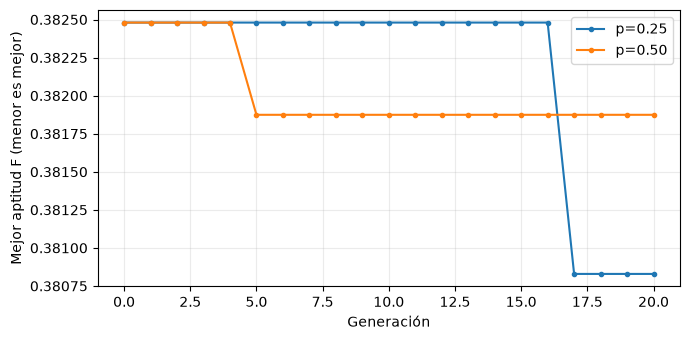

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [16]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


# Desarrollo

## Desarrollo 1. Versión base

La versión base son las funciones de las secciones 3 a 8 y no las cambiamos: `random_individual` crea la población inicial, `tournament` es el torneo de dos, `crossover` la cruza de un punto, `mutate` la mutación de un nivel por gen, `next_generation` el reemplazo con una élite y `run_ga` el ciclo completo.

La variable `variant` de la sección 9 es la corrida con mutación 0.50, que es para Final. Nuestra variante de Desarrollo es otra y está abajo.

## Desarrollo 2. Limitación e hipótesis

Cambiamos la selección.

En el torneo de dos el ganador solo tiene que ser mejor que otro elegido al azar. Con 20 individuos, el mejor entra a un torneo con probabilidad $2/20 = 0.10$ y casi cualquier candidato puede ganar si le toca uno peor. Pensamos que por eso muchos padres son regulares y la búsqueda avanza lento.

En un torneo de tres se eligen tres al azar y gana el de menor $F$. Así el mejor entra con probabilidad $3/20 = 0.15$ y los dos peores de la población nunca ganan.

Hipótesis: si los padres son mejores, los hijos van a quedar más cerca de 1410 m³ sin pasarse, y en las mismas 20 generaciones la variante va a llegar a un plan factible con menos agua potable (menor $F$). El riesgo es que la población se llene de candidatos parecidos y se estanque.

## Desarrollo 3. Código de la variante

Solo cambia la selección: `tournament_variante` es igual a `tournament` pero con `size=3`. `next_generation_variante` y `run_ga_variante` son copias de la base que solo llaman a la función nueva. La cruza, la mutación, el reemplazo y la élite son los mismos.

In [17]:
# torneo de 3: igual que tournament pero con size=3 (este es el unico cambio)
def tournament_variante(population, rng):
    # 3 posiciones distintas al azar (replace=False = sin repetir)
    indices = rng.choice(len(population), size=3, replace=False)
    # gana el de menor F
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    # copia para que cruzar o mutar no cambie al original
    return winner.copy()


# igual que next_generation, solo usa tournament_variante
def next_generation_variante(population, probability, rng):
    # la elite (menor F) pasa sin cambios
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    # se llena hasta tener el mismo tamano que antes (20)
    while len(replacement) < len(population):
        parent_a = tournament_variante(population, rng)
        parent_b = tournament_variante(population, rng)
        child = crossover(parent_a, parent_b, rng)  # misma cruza de la base
        replacement.append(mutate(child, probability, rng))  # misma mutacion de la base
    return replacement


# igual que run_ga, solo usa next_generation_variante
def run_ga_variante(population_size=20, generations=20, mutation_probability=0.25, seed=42):
    # mismas revisiones que run_ga
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    # generador con semilla: misma semilla = mismos resultados
    rng = np.random.default_rng(seed)
    # poblacion inicial igual que en la base
    population = [random_individual(rng) for _ in range(population_size)]
    # history guarda el mejor F de cada generacion (21 valores con la inicial)
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation_variante(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## Desarrollo 4. Condiciones y corridas

Las dos versiones usan lo mismo: 20 individuos, 20 generaciones, semilla 42, mutación 0.25 por gen, los mismos datos y el mismo `evaluate`, la misma población inicial (`random_individual`) y reemplazo generacional con 20 individuos siempre y una élite. Lo único distinto es el torneo de 2 contra el de 3.

Cada corrida crea su propio generador con semilla 42 dentro de `run_ga` o `run_ga_variante`, así que no depende de otras celdas y las dos empiezan con la misma población.

Entorno: usamos `pyproject.toml` y `uv.lock` del kit (`uv sync --locked`). Abajo imprimimos las versiones.

In [18]:
import sys

# versiones del entorno
print("Python", sys.version.split()[0])
print("NumPy", np.__version__)

# cada corrida empieza desde cero con semilla 42
resultado_base = run_ga(population_size=20, generations=20, mutation_probability=0.25, seed=42)
resultado_variante = run_ga_variante(population_size=20, generations=20, mutation_probability=0.25, seed=42)

for nombre, r in [("Base (torneo de 2)", resultado_base), ("Variante (torneo de 3)", resultado_variante)]:
    m = evaluate(r["genes"])  # revisamos con el mismo evaluate
    print()
    print(nombre)
    print("genes:", r["genes"], " fracciones:", r["genes"] / 10)  # /10 pasa de nivel a fraccion
    print("T =", round(m["treated"], 3), "m3   P =", round(m["potable"], 3), "m3")
    print("F =", round(m["fitness"], 6), "  E =", round(m["excess"], 3), "m3")
    print("cumple dominios:", np.all(r["genes"] >= 0) and np.all(r["genes"] <= LIMITS))
    print("cumple capacidad:", m["feasible"])

Python 3.12.3
NumPy 2.3.5

Base (torneo de 2)
genes: [7 4 3 8]  fracciones: [0.7 0.4 0.3 0.8]
T = 1409.363 m3   P = 866.847 m3
F = 0.380829   E = 0.0 m3
cumple dominios: True
cumple capacidad: True

Variante (torneo de 3)
genes: [5 7 4 8]  fracciones: [0.5 0.7 0.4 0.8]
T = 1406.984 m3   P = 869.226 m3
F = 0.381874   E = 0.0 m3
cumple dominios: True
cumple capacidad: True


Mejor $F$ en cada generación (la posición 0 es la población inicial):

Base:      [0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.38248
 0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.38248
 0.38248  0.380829 0.380829 0.380829 0.380829]
Variante:  [0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.38248  0.381874
 0.381874 0.381874 0.381874 0.381874 0.381874 0.381874 0.381874 0.381874
 0.381874 0.381874 0.381874 0.381874 0.381874]


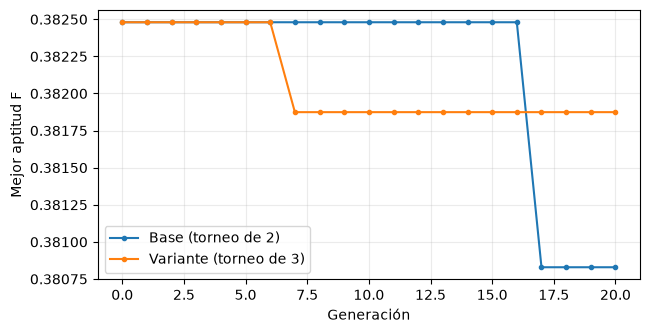

In [19]:
print("Base:     ", np.round(resultado_base["history"], 6))
print("Variante: ", np.round(resultado_variante["history"], 6))

# grafica del mejor F por generacion (si baja es que mejoro)
plt.figure(figsize=(7, 3.5))
plt.plot(resultado_base["history"], marker=".", label="Base (torneo de 2)")
plt.plot(resultado_variante["history"], marker=".", label="Variante (torneo de 3)")
plt.xlabel("Generación")
plt.ylabel("Mejor aptitud F")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Desarrollo 5. Revisamos el ciclo de la variante

Corremos la variante generación por generación y revisamos que siempre haya 20 individuos, que los genes estén en su dominio y que el mejor $F$ no empeore (la élite se conserva). Al final vemos que sale lo mismo que con `run_ga_variante`.

In [20]:
# mismo inicio que run_ga_variante
rng = np.random.default_rng(42)
poblacion = [random_individual(rng) for _ in range(20)]

for generacion in range(1, 21):
    mejor_antes = min(evaluate(x)["fitness"] for x in poblacion)
    poblacion = next_generation_variante(poblacion, 0.25, rng)
    mejor_despues = min(evaluate(x)["fitness"] for x in poblacion)
    assert len(poblacion) == 20  # poblacion constante
    for x in poblacion:
        assert np.all(x >= 0) and np.all(x <= LIMITS)  # genes en su dominio
    assert mejor_despues <= mejor_antes  # la elite no deja que empeore

mejor = min(poblacion, key=lambda x: evaluate(x)["fitness"])
np.testing.assert_array_equal(mejor, resultado_variante["genes"])  # mismo resultado
print("20 generaciones: siempre 20 individuos, genes validos y la elite se conserva.")
print("Mejor de la ultima poblacion:", mejor)

20 generaciones: siempre 20 individuos, genes validos y la elite se conserva.
Mejor de la ultima poblacion: [5 7 4 8]


## Desarrollo 6. Repetimos las dos versiones

Volvemos a correr base y variante desde el inicio con semilla 42 y revisamos que salgan los mismos genes y la misma historia.

In [21]:
base_otra_vez = run_ga(population_size=20, generations=20, mutation_probability=0.25, seed=42)
variante_otra_vez = run_ga_variante(population_size=20, generations=20, mutation_probability=0.25, seed=42)

# si algo no fuera igual, estas lineas marcan error
np.testing.assert_array_equal(resultado_base["genes"], base_otra_vez["genes"])
np.testing.assert_array_equal(resultado_base["history"], base_otra_vez["history"])
np.testing.assert_array_equal(resultado_variante["genes"], variante_otra_vez["genes"])
np.testing.assert_array_equal(resultado_variante["history"], variante_otra_vez["history"])
print("Base y variante se repiten igual con semilla 42.")

Base y variante se repiten igual con semilla 42.


## Desarrollo 7. Resultados

| Medida | Base (torneo de 2) | Variante (torneo de 3) |
|---|---|---|
| Cromosoma final $(k_1, k_2, k_3, k_4)$ | (7, 4, 3, 8) | (5, 7, 4, 8) |
| Fracciones | 0.7, 0.4, 0.3, 0.8 | 0.5, 0.7, 0.4, 0.8 |
| Agua tratada $T$ (m³) | 1409.363 | 1406.984 |
| Agua potable $P$ (m³) | 866.847 | 869.226 |
| Aptitud $F$ | 0.380829 | 0.381874 |
| Exceso $E$ (m³) | 0 | 0 |
| Dominios | cumple | cumple |
| Capacidad ($T \le 1410$) | cumple | cumple |
| Generación donde llegó a su mejor $F$ | 17 | 7 |

Para tener una referencia revisamos las 5103 combinaciones con `evaluate`. Esto no es parte del algoritmo.

In [22]:
# probamos todas las combinaciones (9 * 9 * 7 * 9 = 5103) solo como referencia
mejor_k = None
mejor_F = 2  # cualquier F real es menor que 2
for k1 in range(9):
    for k2 in range(9):
        for k3 in range(7):
            for k4 in range(9):
                F = evaluate(np.array([k1, k2, k3, k4]))["fitness"]
                if F < mejor_F:
                    mejor_F = F
                    mejor_k = (k1, k2, k3, k4)

print("Mejor de las 5103:", mejor_k)
print(evaluate(np.array(mejor_k)))

Mejor de las 5103: (8, 6, 4, 5)
{'treated': 1409.984, 'potable': 866.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.38055627556332683}


## Desarrollo 8. Interpretación

Los dos planes son factibles (genes en su dominio y $T$ menor a 1410 m³), así que sí se puede comparar el agua potable. La base usa 866.847 m³ y la variante 869.226 m³, o sea 2.379 m³ más. La base tiene menor $F$ (0.380829 contra 0.381874), entonces en esta corrida la variante salió peor y no se cumplió nuestra hipótesis.

Las dos empiezan con el mismo mejor $F$ (0.38248), así que sí partieron de la misma población. La variante mejoró antes, en la generación 7, y la base hasta la 17. Eso sí va con que el torneo de tres presiona más. Pero después la variante ya no mejoró en 13 generaciones. Creemos que pasó el riesgo que dijimos: los padres se parecen más, la cruza junta candidatos casi iguales y solo la mutación cambia algo, entonces se quedó en un plan bueno pero no el mejor. No medimos qué tan parecida era la población, así que esto es lo que creemos y no algo que comprobamos.

En agua, los dos usan casi toda la capacidad. Como $P = Q - T$, lo que importa es acercarse a 1410 m³ sin pasarse. A la base le sobran 0.637 m³ y a la variante 3.016 m³. La base pone 70 % en Aulas 1 y 80 % en Aulas 2, que son los edificios que más consumen; la variante pone 50 % en Aulas 1 y sube Biblioteca a 70 %.

El mejor plan posible es (8, 6, 4, 5) con $T = 1409.984$ m³, $P = 866.226$ m³ y $F = 0.380556$. Ninguna versión lo encontró: la base quedó a 0.621 m³ de potable de ese plan y la variante a 3.000 m³.

Esto es una sola corrida con semilla 42. Con otra semilla cambian la población inicial y los torneos, y podría salir al revés. Además la diferencia es chica, 2.379 m³, como 0.1 % de la demanda. Para saber cuál es mejor en general habría que correr muchas semillas y comparar promedios. Con lo que tenemos solo podemos decir que en esta corrida la base terminó mejor.

Conclusión: cambiamos solo la selección y usamos las mismas condiciones. La variante llegó antes a un buen plan pero se quedó ahí, y la base terminó con un plan factible que usa 2.379 m³ menos de agua potable.